# Sudoku 9x9 con Deep Reinforcement Learning (DQN + PyTorch)

Un agente de Deep Q-Network (DQN) que aprende a resolver puzzles de Sudoku 9x9 usando redes neuronales convolucionales en PyTorch.

---

## ¿Por qué necesitamos Deep RL para Sudoku 9x9?

En el notebook anterior resolvimos Sudoku 4x4 con **Q-Learning tabular** (una tabla de valores Q). ¿Por qué no funciona lo mismo para 9x9?

### El problema de la escala

| Aspecto | Sudoku 4x4 | Sudoku 9x9 |
|---|---|---|
| Celdas | 16 | 81 |
| Valores por celda | 0-4 (5 posibles) | 0-9 (10 posibles) |
| Estados posibles | $5^{16} \approx 10^{11}$ | $10^{81} \approx 10^{81}$ |
| Acciones posibles | $16 \times 4 = 64$ | $81 \times 9 = 729$ |
| Q-table tabular | ✅ Cabe en memoria | ❌ Imposible ($10^{81} \times 729$) |

**Es imposible** almacenar una tabla Q para todos los estados de un Sudoku 9x9. Necesitamos una **función que aproxime** los valores Q: una **red neuronal**.

### La solución: Deep Q-Network (DQN)

En lugar de una tabla, usamos una **red neuronal** $Q_\theta(s, a)$ que:
- **Entrada**: el estado del tablero (codificado como tensor)
- **Salida**: Q-values para todas las acciones posibles
- **Aprende** a generalizar: estados similares → Q-values similares

$$Q_{\text{tabla}}[s][a] \quad \longrightarrow \quad Q_\theta(s, a) = \text{RedNeuronal}(s)[a]$$

### Arquitectura general

```
Tablero 9x9          Red Neuronal (DQN)              Q-values
┌─────────┐     ┌─────────────────────────┐     ┌──────────────┐
│ 5 3 0 0 │     │                         │     │ Q(s, (0,2,1))│
│ 6 0 0 1 │ ──→ │  CNN + Capas Densas     │ ──→ │ Q(s, (0,2,2))│
│ 0 9 8 0 │     │  (PyTorch)              │     │ Q(s, (0,2,3))│
│ ...     │     │                         │     │ ...729 total │
└─────────┘     └─────────────────────────┘     └──────────────┘
  (9×9×10)          Parámetros θ                   (729 valores)
```

### Componentes clave de DQN

DQN (Mnih et al., 2015) introduce dos innovaciones críticas:

1. **Experience Replay**: almacenar transiciones $(s, a, r, s')$ en un buffer y muestrear mini-batches aleatorios. Esto rompe la correlación temporal entre datos consecutivos.

2. **Target Network**: una copia de la red que se actualiza periódicamente. Esto estabiliza el entrenamiento al evitar que el objetivo se mueva constantemente.

$$\mathscr{L}(\theta) = \mathbb{E}\left[\left(r + \gamma \max_{a'} Q_{\theta^-}(s', a') - Q_\theta(s, a)\right)^2\right]$$

donde $\theta^-$ son los pesos de la **target network** (copia congelada).

In [2]:
# Instalar PyTorch si no está disponible
try:
    import torch
    print(f'PyTorch {torch.__version__} disponible ✓')
    print(f'CUDA disponible: {torch.cuda.is_available()}')
except ImportError:
    print('Instalando PyTorch...')
    !pip install torch torchvision -q
    import torch
    print(f'PyTorch {torch.__version__} instalado ✓')

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import random
from copy import deepcopy
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {device}')

PyTorch 2.10.0+cu128 disponible ✓
CUDA disponible: True
Dispositivo: cuda


---

## Paso 1: El entorno Sudoku 9x9

Construimos un entorno completo que:
- Genera puzzles válidos de Sudoku 9x9
- Verifica restricciones (fila, columna, subcuadrante 3x3)
- Codifica el tablero como tensor para la red neuronal

Forma del estado codificado: (10, 9, 9)
  Canal 0 (vacías): 30 celdas vacías
  Canales 1-9: one-hot de dígitos
  Total acciones: 729
  Acciones válidas: 41 de 729


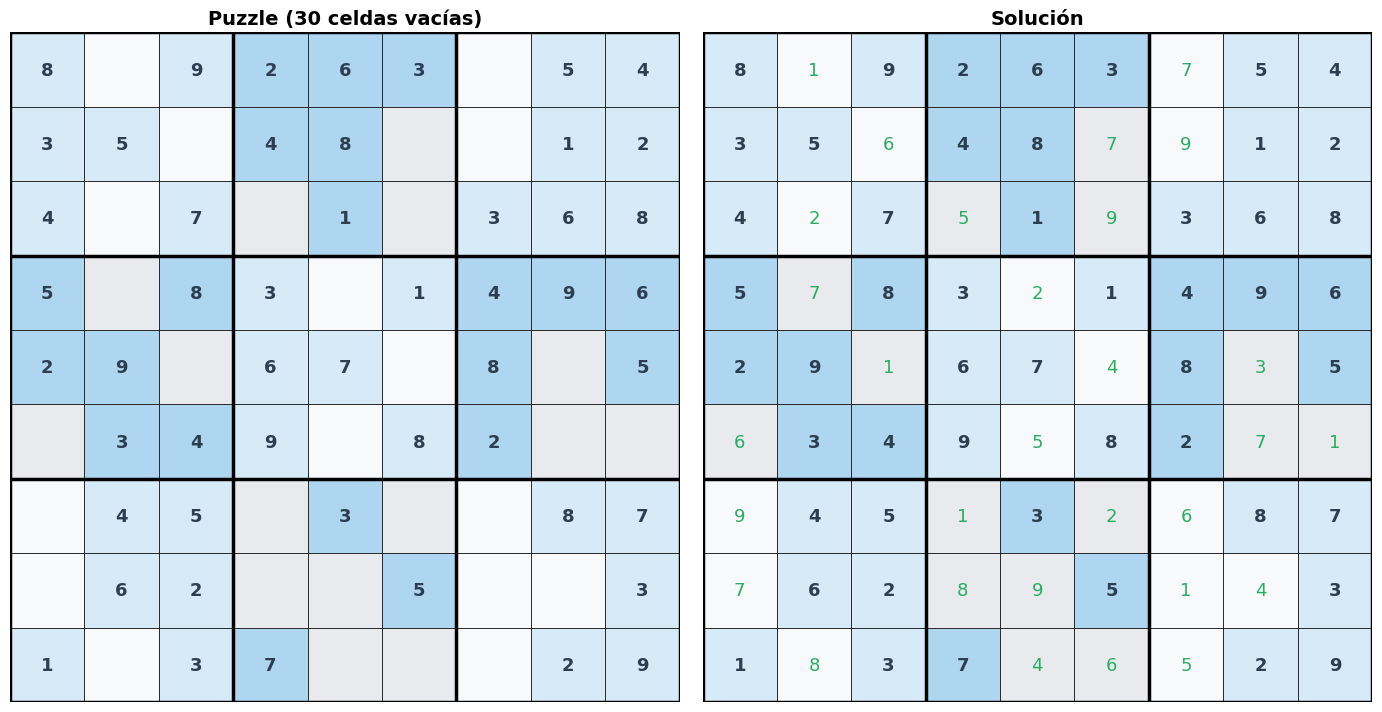

In [3]:
class Sudoku9x9Env:
    """
    Entorno de Sudoku 9x9 para Deep Reinforcement Learning.

    El tablero se codifica como un tensor de forma (10, 9, 9):
    - Canal 0: máscara de celdas vacías (1 si vacía, 0 si ocupada)
    - Canales 1-9: one-hot encoding del dígito en cada celda

    Acciones: 729 posibles = 81 celdas × 9 dígitos
    - Acción k → celda (k // 9), dígito (k % 9) + 1

    Parámetros
    ----------
    n_vacias : int
        Número de celdas vacías (dificultad). Default 30.
    """

    N_ACCIONES = 729  # 81 celdas × 9 dígitos

    def __init__(self, n_vacias=30):
        self.size = 9
        self.box_size = 3
        self.n_vacias = n_vacias
        self.tablero = None
        self.solucion = None
        self.celdas_fijas = None
        self.n_vacias_actual = 0

    # =========================================================
    # Generación de puzzles
    # =========================================================

    def _es_valido(self, tablero, fila, col, num):
        """Verifica si 'num' puede ir en (fila, col) sin violar restricciones."""
        # Fila
        if num in tablero[fila]:
            return False
        # Columna
        if num in tablero[:, col]:
            return False
        # Subcuadrante 3x3
        sf = (fila // 3) * 3
        sc = (col // 3) * 3
        if num in tablero[sf:sf+3, sc:sc+3]:
            return False
        return True

    def _generar_solucion(self):
        """
        Genera una solución válida completa de Sudoku 9x9
        usando backtracking con aleatorización.
        """
        tablero = np.zeros((9, 9), dtype=int)

        def llenar(tab):
            for i in range(9):
                for j in range(9):
                    if tab[i, j] == 0:
                        nums = list(range(1, 10))
                        np.random.shuffle(nums)
                        for num in nums:
                            if self._es_valido(tab, i, j, num):
                                tab[i, j] = num
                                if llenar(tab):
                                    return True
                                tab[i, j] = 0
                        return False
            return True

        llenar(tablero)
        return tablero

    def reset(self):
        """
        Genera un nuevo puzzle. Retorna el estado codificado.

        Retorna
        -------
        estado : np.array de forma (10, 9, 9)
            Estado codificado del tablero.
        """
        self.solucion = self._generar_solucion()
        self.tablero = self.solucion.copy()

        # Vaciar celdas aleatoriamente
        celdas = [(i, j) for i in range(9) for j in range(9)]
        np.random.shuffle(celdas)
        for (i, j) in celdas[:self.n_vacias]:
            self.tablero[i, j] = 0

        self.celdas_fijas = set()
        for i in range(9):
            for j in range(9):
                if self.tablero[i, j] != 0:
                    self.celdas_fijas.add((i, j))

        self.n_vacias_actual = np.sum(self.tablero == 0)
        return self._codificar_estado()

    # =========================================================
    # Codificación del estado
    # =========================================================

    def _codificar_estado(self):
        """
        Codifica el tablero como tensor (10, 9, 9).

        Canal 0: máscara de vacías (1=vacía, 0=ocupada)
        Canal k (1-9): 1 si la celda contiene el dígito k

        Esta codificación one-hot permite que la CNN
        procese el tablero como si fuera una "imagen"
        multicanal.
        """
        estado = np.zeros((10, 9, 9), dtype=np.float32)

        # Canal 0: máscara de vacías
        estado[0] = (self.tablero == 0).astype(np.float32)

        # Canales 1-9: one-hot del dígito
        for d in range(1, 10):
            estado[d] = (self.tablero == d).astype(np.float32)

        return estado

    # =========================================================
    # Decodificación de acciones
    # =========================================================

    def _decodificar_accion(self, accion_idx):
        """
        Convierte índice de acción (0-728) en (fila, col, num).

        accion_idx = celda_idx * 9 + (num - 1)
        celda_idx = fila * 9 + col
        """
        celda_idx = accion_idx // 9
        num = (accion_idx % 9) + 1
        fila = celda_idx // 9
        col = celda_idx % 9
        return fila, col, num

    def _codificar_accion(self, fila, col, num):
        """Convierte (fila, col, num) en índice de acción."""
        celda_idx = fila * 9 + col
        return celda_idx * 9 + (num - 1)

    # =========================================================
    # Máscara de acciones válidas
    # =========================================================

    def obtener_mascara_acciones(self):
        """
        Retorna un vector binario (729,) donde 1 = acción válida.

        Esto es CRUCIAL para el DQN: solo consideramos acciones
        que no violan las restricciones del Sudoku.
        """
        mascara = np.zeros(self.N_ACCIONES, dtype=np.float32)

        for i in range(9):
            for j in range(9):
                if self.tablero[i, j] == 0:  # solo celdas vacías
                    for num in range(1, 10):
                        if self._es_valido(self.tablero, i, j, num):
                            idx = self._codificar_accion(i, j, num)
                            mascara[idx] = 1.0

        return mascara

    # =========================================================
    # Step
    # =========================================================

    def step(self, accion_idx):
        """
        Ejecuta una acción.

        Parámetros
        ----------
        accion_idx : int (0-728)
            Índice de la acción.

        Retorna
        -------
        estado : array (10, 9, 9)
        recompensa : float
        terminado : bool
        info : dict
        """
        fila, col, num = self._decodificar_accion(accion_idx)
        info = {'fila': fila, 'col': col, 'num': num, 'valido': False,
                'correcto': False, 'completo': False}

        # ¿Celda fija?
        if (fila, col) in self.celdas_fijas:
            return self._codificar_estado(), -2.0, False, info

        # ¿Celda ya ocupada?
        if self.tablero[fila, col] != 0:
            return self._codificar_estado(), -2.0, False, info

        # ¿Movimiento válido?
        if self._es_valido(self.tablero, fila, col, num):
            self.tablero[fila, col] = num
            info['valido'] = True
            self.n_vacias_actual -= 1

            # ¿Es el número correcto?
            es_correcto = (num == self.solucion[fila, col])
            info['correcto'] = es_correcto

            # Recompensas
            if es_correcto:
                recompensa = 5.0  # Número correcto
            else:
                recompensa = -3.0  # Válido pero incorrecto

            # ¿Puzzle completo?
            if self.n_vacias_actual == 0:
                info['completo'] = True
                if np.array_equal(self.tablero, self.solucion):
                    return self._codificar_estado(), 50.0, True, info  # ¡Resuelto!
                else:
                    return self._codificar_estado(), -10.0, True, info

            return self._codificar_estado(), recompensa, False, info
        else:
            # Movimiento inválido
            return self._codificar_estado(), -5.0, False, info

    def esta_resuelto(self):
        """Verifica si el Sudoku ha sido resuelto correctamente."""
        return self.n_vacias_actual == 0 and np.array_equal(self.tablero, self.solucion)

    # =========================================================
    # Visualización
    # =========================================================

    def render(self, titulo='Sudoku 9x9', ax=None, mostrar_solucion=False):
        """Renderiza el tablero con matplotlib."""
        show = False
        if ax is None:
            fig, ax = plt.subplots(figsize=(7, 7))
            show = True

        tab = self.solucion if mostrar_solucion else self.tablero

        for i in range(9):
            for j in range(9):
                # Color de fondo por subcuadrante
                box = (i // 3) * 3 + (j // 3)
                bg = '#F8F9FA' if box % 2 == 0 else '#E8EAED'

                if (i, j) in self.celdas_fijas:
                    bg = '#D6EAF8' if box % 2 == 0 else '#AED6F1'
                elif tab[i, j] != 0 and not mostrar_solucion:
                    bg = '#D5F5E3'  # verde para colocadas por agente

                rect = plt.Rectangle((j, 8-i), 1, 1, facecolor=bg,
                                    edgecolor='gray', linewidth=0.5)
                ax.add_patch(rect)

                if tab[i, j] != 0:
                    peso = 'bold' if (i, j) in self.celdas_fijas else 'normal'
                    clr = '#2C3E50' if (i, j) in self.celdas_fijas else '#27AE60'
                    ax.text(j+0.5, 8-i+0.5, str(tab[i, j]),
                           ha='center', va='center', fontsize=13,
                           fontweight=peso, color=clr)

        # Líneas gruesas para subcuadrantes 3x3
        for k in range(10):
            lw = 2.5 if k % 3 == 0 else 0.5
            ax.plot([0, 9], [k, k], 'k-', linewidth=lw)
            ax.plot([k, k], [0, 9], 'k-', linewidth=lw)

        ax.set_xlim(0, 9); ax.set_ylim(0, 9)
        ax.set_aspect('equal'); ax.axis('off')
        ax.set_title(titulo, fontsize=14, fontweight='bold')
        if show:
            plt.tight_layout(); plt.show()


# === Prueba del entorno ===
np.random.seed(42)
env = Sudoku9x9Env(n_vacias=30)
estado = env.reset()

print(f'Forma del estado codificado: {estado.shape}')
print(f'  Canal 0 (vacías): {estado[0].sum():.0f} celdas vacías')
print(f'  Canales 1-9: one-hot de dígitos')
print(f'  Total acciones: {env.N_ACCIONES}')

mascara = env.obtener_mascara_acciones()
print(f'  Acciones válidas: {int(mascara.sum())} de {env.N_ACCIONES}')

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
env.render('Puzzle (30 celdas vacías)', ax=axes[0])
env.render('Solución', ax=axes[1], mostrar_solucion=True)
plt.tight_layout(); plt.show()

---

## Paso 2: Codificación del estado (detalle)

La codificación del tablero es **crítica** para que la red neuronal pueda aprender. Veamos exactamente qué recibe la red.

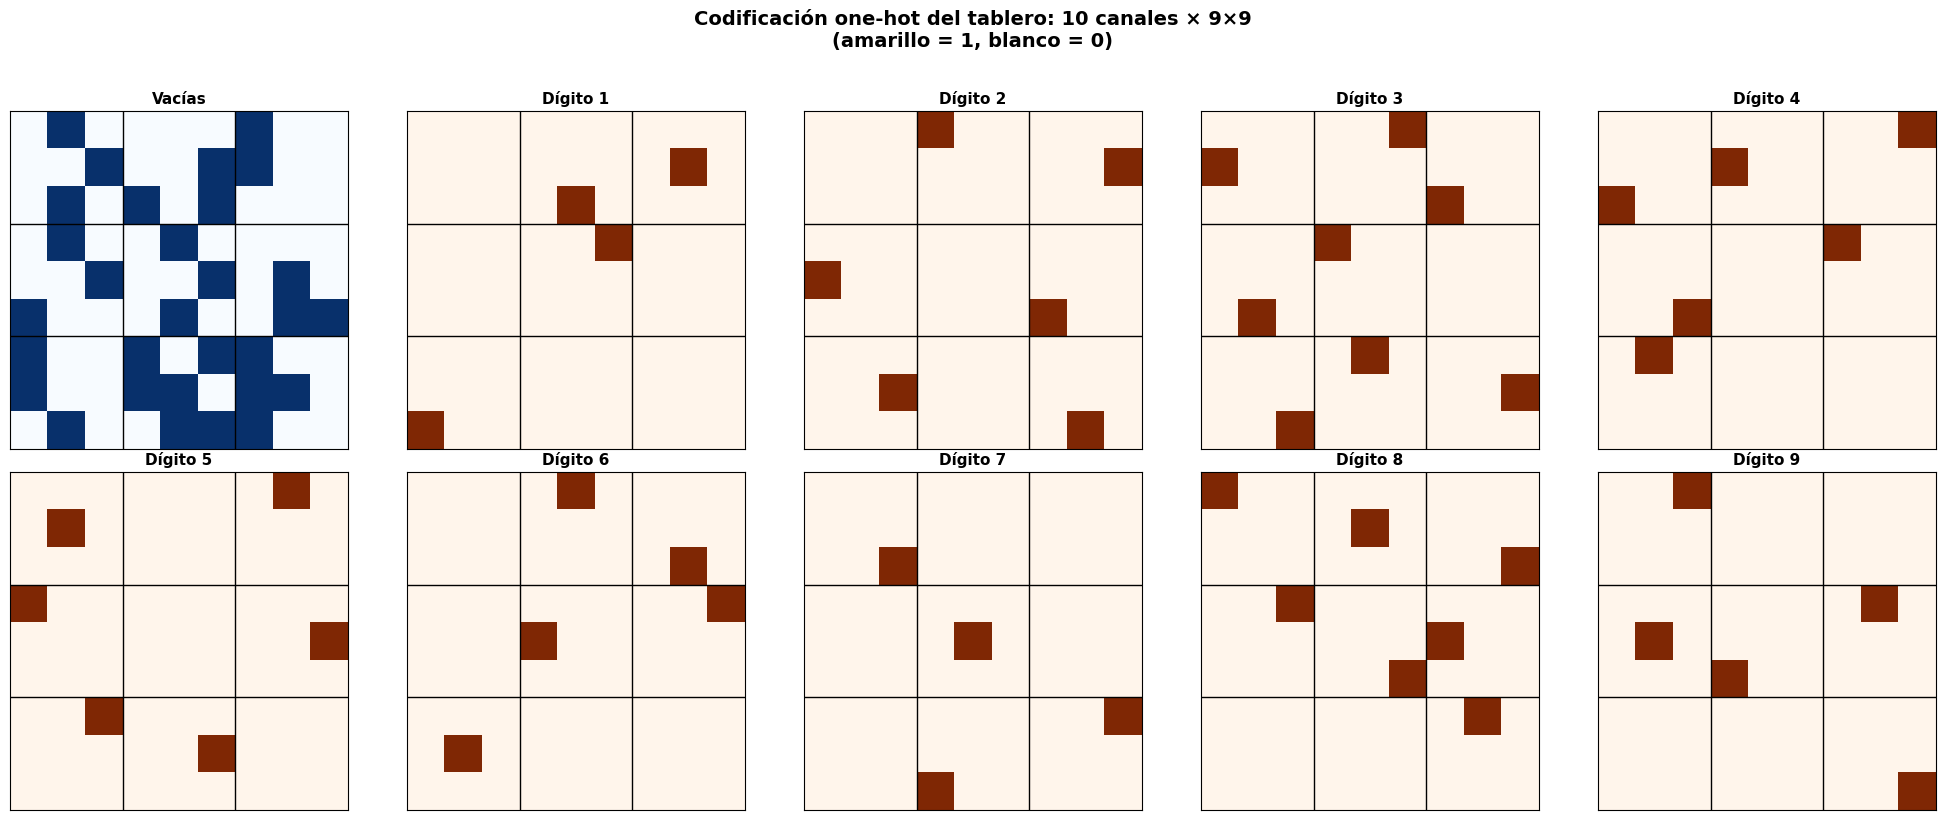

Forma del tensor de entrada a la red: (batch, 10, 9, 9)
  - Es como una "imagen" de 9×9 con 10 canales
  - Canal 0: dónde están las celdas vacías (lo que el agente debe llenar)
  - Canales 1-9: dónde está cada dígito actualmente
  - Total parámetros por estado: 810 = 810 valores float


In [4]:
# Visualizar la codificación one-hot del tablero
np.random.seed(42)
env_cod = Sudoku9x9Env(n_vacias=30)
estado = env_cod.reset()

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

nombres_canales = ['Vacías', 'Dígito 1', 'Dígito 2', 'Dígito 3', 'Dígito 4',
                   'Dígito 5', 'Dígito 6', 'Dígito 7', 'Dígito 8', 'Dígito 9']

for idx in range(10):
    ax = axes[idx // 5, idx % 5]
    im = ax.imshow(estado[idx], cmap='Blues' if idx == 0 else 'Oranges',
                   interpolation='nearest', vmin=0, vmax=1)
    ax.set_title(nombres_canales[idx], fontsize=11, fontweight='bold')

    # Líneas de subcuadrantes
    for k in [2.5, 5.5]:
        ax.axhline(y=k, color='black', linewidth=1)
        ax.axvline(x=k, color='black', linewidth=1)

    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Codificación one-hot del tablero: 10 canales × 9×9\n'
             '(amarillo = 1, blanco = 0)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

print('Forma del tensor de entrada a la red: (batch, 10, 9, 9)')
print(f'  - Es como una "imagen" de 9×9 con 10 canales')
print(f'  - Canal 0: dónde están las celdas vacías (lo que el agente debe llenar)')
print(f'  - Canales 1-9: dónde está cada dígito actualmente')
print(f'  - Total parámetros por estado: {10 * 9 * 9} = {10*9*9} valores float')

---

## Paso 3: La red neuronal DQN (Deep Q-Network)

Construimos la arquitectura en PyTorch. Usamos:
- **Capas convolucionales**: para detectar patrones locales (subcuadrantes, filas, columnas)
- **Capas densas**: para combinar la información y producir Q-values
- **Máscara de acciones**: para ignorar acciones inválidas

In [5]:
class DQN(nn.Module):
    """
    Deep Q-Network para Sudoku 9x9.

    Arquitectura:
    - 3 capas convolucionales (detectan patrones en el tablero)
    - 2 capas densas (combinan información global)
    - Salida: 729 Q-values (81 celdas × 9 dígitos)

    La red recibe:
    - estado: tensor (batch, 10, 9, 9) — tablero codificado
    - mascara: tensor (batch, 729) — 1 para acciones válidas

    Retorna:
    - Q-values: tensor (batch, 729) — con -inf en acciones inválidas
    """

    def __init__(self):
        super(DQN, self).__init__()

        # === Capas convolucionales ===
        # Conv1: 10 canales → 64 filtros, kernel 3x3
        # Detecta patrones locales (subcuadrantes 3x3)
        self.conv1 = nn.Conv2d(
            in_channels=10,    # 10 canales de entrada (vacías + 9 dígitos)
            out_channels=64,   # 64 filtros (features a detectar)
            kernel_size=3,     # Kernel 3x3 (tamaño de subcuadrante!)
            padding=1          # Padding para mantener dimensiones 9x9
        )

        # Conv2: 64 → 128 filtros
        # Combina patrones de nivel medio
        self.conv2 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        # Conv3: 128 → 128 filtros
        # Patrones de alto nivel
        self.conv3 = nn.Conv2d(
            in_channels=128,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        # Batch normalization (estabiliza el entrenamiento)
        self.bn1 = nn.BatchNorm2d(64)
        self.bn2 = nn.BatchNorm2d(128)
        self.bn3 = nn.BatchNorm2d(128)

        # === Capas densas ===
        # Después de conv: 128 canales × 9 × 9 = 10368 features
        self.fc1 = nn.Linear(128 * 9 * 9, 512)
        self.fc2 = nn.Linear(512, 729)  # 729 Q-values de salida

        # Dropout para regularización
        self.dropout = nn.Dropout(0.2)

    def forward(self, estado, mascara=None):
        """
        Forward pass.

        Parámetros
        ----------
        estado : tensor (batch, 10, 9, 9)
            Tablero codificado.
        mascara : tensor (batch, 729), opcional
            1 para acciones válidas, 0 para inválidas.

        Retorna
        -------
        q_values : tensor (batch, 729)
        """
        # Capas convolucionales con ReLU y BatchNorm
        x = F.relu(self.bn1(self.conv1(estado)))  # (batch, 64, 9, 9)
        x = F.relu(self.bn2(self.conv2(x)))       # (batch, 128, 9, 9)
        x = F.relu(self.bn3(self.conv3(x)))       # (batch, 128, 9, 9)

        # Aplanar para capas densas
        x = x.view(x.size(0), -1)                 # (batch, 10368)

        # Capas densas
        x = F.relu(self.fc1(x))                   # (batch, 512)
        x = self.dropout(x)
        q_values = self.fc2(x)                     # (batch, 729)

        # Aplicar máscara: poner -inf en acciones inválidas
        # Así argmax nunca elige una acción inválida
        if mascara is not None:
            q_values = q_values.masked_fill(mascara == 0, -1e9)

        return q_values


# === Crear y examinar la red ===
modelo = DQN().to(device)

# Contar parámetros
total_params = sum(p.numel() for p in modelo.parameters())
trainable_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)

print('Arquitectura de la DQN:')
print('=' * 60)
print(modelo)
print('=' * 60)
print(f'\nParámetros totales: {total_params:,}')
print(f'Parámetros entrenables: {trainable_params:,}')

# Prueba forward pass
estado_tensor = torch.FloatTensor(estado).unsqueeze(0).to(device)  # (1, 10, 9, 9)
mascara_tensor = torch.FloatTensor(mascara).unsqueeze(0).to(device)  # (1, 729)

with torch.no_grad():
    q_vals = modelo(estado_tensor, mascara_tensor)

print(f'\nForward pass:')
print(f'  Entrada: {estado_tensor.shape}')
print(f'  Máscara: {mascara_tensor.shape}')
print(f'  Salida Q-values: {q_vals.shape}')
print(f'  Mejor acción: {q_vals.argmax().item()}')

# Decodificar
mejor = q_vals.argmax().item()
f, c, n = env._decodificar_accion(mejor)
print(f'  → Poner {n} en ({f},{c})')

Arquitectura de la DQN:
DQN(
  (conv1): Conv2d(10, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=10368, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=729, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)

Parámetros totales: 5,910,809
Parámetros entrenables: 5,910,809

Forward pass:
  Entrada: torch.Size([1, 10, 9, 9])
  Máscara: torch.Size([1, 729])
  Salida Q-values: torch.Size([1, 729])
  Mejor acción: 474
  → Poner 7 en (5,7)


---

## Paso 4: Visualización de la arquitectura

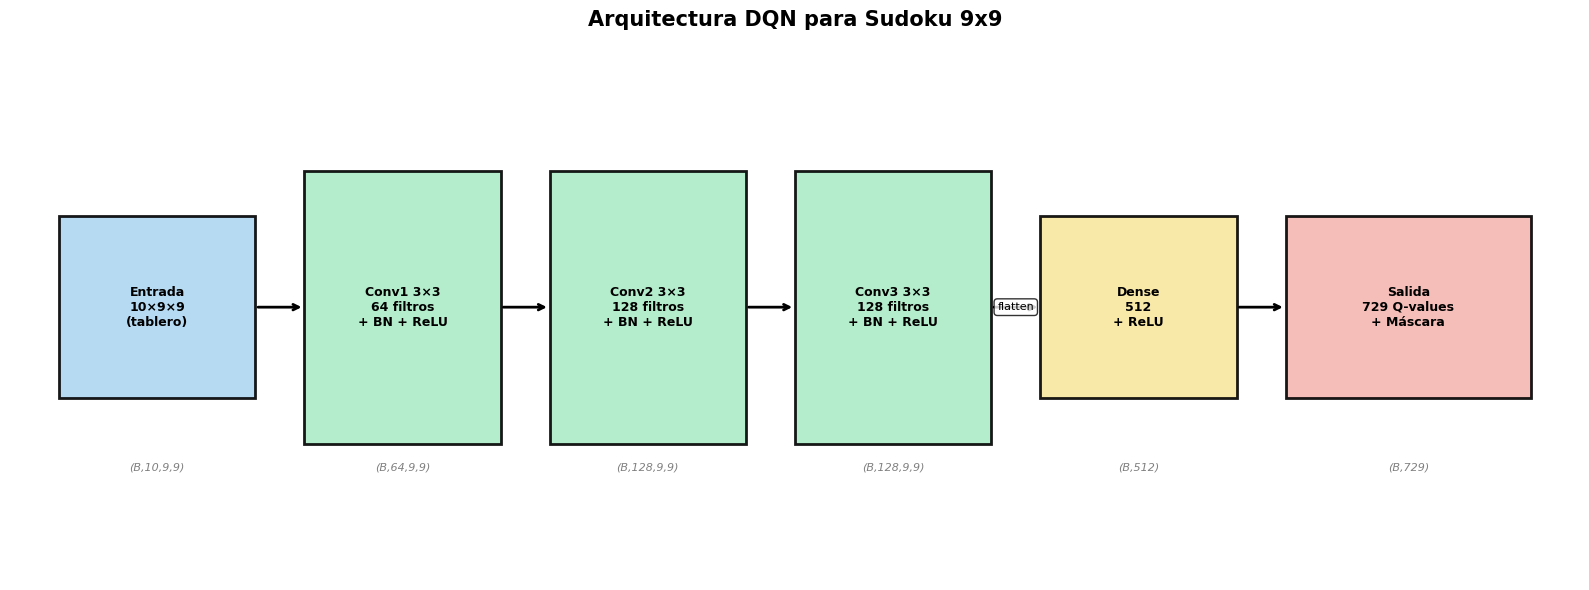

¿Por qué esta arquitectura?
• Conv 3×3: el kernel coincide con el tamaño del subcuadrante 3x3
• 3 capas conv: detectan restricciones locales → regionales → globales
• BatchNorm: estabiliza el entrenamiento de las convoluciones
• Máscara de acciones: la red NUNCA elige una acción inválida


In [6]:
# Diagrama de la arquitectura
fig, ax = plt.subplots(figsize=(16, 6))
ax.set_xlim(0, 16); ax.set_ylim(0, 6); ax.axis('off')

# Bloques
bloques = [
    (0.5, 2, 2, 2, '#AED6F1', 'Entrada\n10×9×9\n(tablero)'),
    (3, 1.5, 2, 3, '#ABEBC6', 'Conv1 3×3\n64 filtros\n+ BN + ReLU'),
    (5.5, 1.5, 2, 3, '#ABEBC6', 'Conv2 3×3\n128 filtros\n+ BN + ReLU'),
    (8, 1.5, 2, 3, '#ABEBC6', 'Conv3 3×3\n128 filtros\n+ BN + ReLU'),
    (10.5, 2, 2, 2, '#F9E79F', 'Dense\n512\n+ ReLU'),
    (13, 2, 2.5, 2, '#F5B7B1', 'Salida\n729 Q-values\n+ Máscara'),
]

for x, y, w, h, color, texto in bloques:
    rect = plt.Rectangle((x, y), w, h, facecolor=color, edgecolor='black', linewidth=2, alpha=0.9)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, texto, ha='center', va='center', fontsize=9, fontweight='bold')

# Flechas
for x1, x2 in [(2.5, 3), (5, 5.5), (7.5, 8), (10, 10.5), (12.5, 13)]:
    ax.annotate('', xy=(x2, 3), xytext=(x1, 3),
               arrowprops=dict(arrowstyle='->', color='black', lw=2))

# Flatten
ax.text(10.25, 3, 'flatten', fontsize=8, ha='center', va='center',
       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Dimensiones
dims = ['(B,10,9,9)', '(B,64,9,9)', '(B,128,9,9)', '(B,128,9,9)', '(B,512)', '(B,729)']
xs = [1.5, 4, 6.5, 9, 11.5, 14.25]
for x, dim in zip(xs, dims):
    ax.text(x, 1.2, dim, ha='center', fontsize=8, fontstyle='italic', color='gray')

ax.set_title('Arquitectura DQN para Sudoku 9x9', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

print('¿Por qué esta arquitectura?')
print('• Conv 3×3: el kernel coincide con el tamaño del subcuadrante 3x3')
print('• 3 capas conv: detectan restricciones locales → regionales → globales')
print('• BatchNorm: estabiliza el entrenamiento de las convoluciones')
print('• Máscara de acciones: la red NUNCA elige una acción inválida')

---

## Paso 5: Experience Replay Buffer

El replay buffer almacena transiciones $(s, a, r, s', \text{done}, \text{mask}')$ y permite muestrear mini-batches aleatorios para entrenar la red.

In [7]:
class ReplayBuffer:
    """
    Buffer de experiencias para DQN.

    Almacena transiciones (s, a, r, s', done, mask') y permite
    muestrear mini-batches aleatorios para romper la correlación
    temporal entre muestras consecutivas.

    Parámetros
    ----------
    capacidad : int
        Número máximo de transiciones almacenadas.
    """

    def __init__(self, capacidad=50000):
        self.buffer = deque(maxlen=capacidad)

    def agregar(self, estado, accion, recompensa, nuevo_estado, terminado, mascara_nueva):
        """
        Agrega una transición al buffer.

        Parámetros
        ----------
        estado : array (10, 9, 9)
        accion : int (0-728)
        recompensa : float
        nuevo_estado : array (10, 9, 9)
        terminado : bool
        mascara_nueva : array (729,) — máscara del nuevo estado
        """
        self.buffer.append((
            estado, accion, recompensa,
            nuevo_estado, terminado, mascara_nueva
        ))

    def muestrear(self, batch_size):
        """
        Muestrea un mini-batch aleatorio.

        Retorna
        -------
        Tupla de tensores (estados, acciones, recompensas,
                           nuevos_estados, terminados, mascaras)
        """
        batch = random.sample(self.buffer, batch_size)

        estados = torch.FloatTensor(np.array([t[0] for t in batch])).to(device)
        acciones = torch.LongTensor([t[1] for t in batch]).to(device)
        recompensas = torch.FloatTensor([t[2] for t in batch]).to(device)
        nuevos_estados = torch.FloatTensor(np.array([t[3] for t in batch])).to(device)
        terminados = torch.FloatTensor([float(t[4]) for t in batch]).to(device)
        mascaras = torch.FloatTensor(np.array([t[5] for t in batch])).to(device)

        return estados, acciones, recompensas, nuevos_estados, terminados, mascaras

    def __len__(self):
        return len(self.buffer)


# Prueba
buffer = ReplayBuffer(capacidad=10000)

# Simular algunas transiciones
env_test = Sudoku9x9Env(n_vacias=20)
estado = env_test.reset()
mascara = env_test.obtener_mascara_acciones()

for _ in range(100):
    acciones_validas = np.where(mascara > 0)[0]
    if len(acciones_validas) == 0:
        break
    accion = np.random.choice(acciones_validas)
    nuevo_estado, recompensa, done, info = env_test.step(accion)
    nueva_mascara = env_test.obtener_mascara_acciones()

    buffer.agregar(estado, accion, recompensa, nuevo_estado, done, nueva_mascara)

    if done:
        estado = env_test.reset()
        mascara = env_test.obtener_mascara_acciones()
    else:
        estado = nuevo_estado
        mascara = nueva_mascara

print(f'Buffer tiene {len(buffer)} transiciones')

# Muestrear un batch
s, a, r, ns, d, m = buffer.muestrear(16)
print(f'\nMini-batch de tamaño 16:')
print(f'  Estados: {s.shape}')
print(f'  Acciones: {a.shape}')
print(f'  Recompensas: {r.shape}')
print(f'  Nuevos estados: {ns.shape}')
print(f'  Terminados: {d.shape}')
print(f'  Máscaras: {m.shape}')

Buffer tiene 18 transiciones

Mini-batch de tamaño 16:
  Estados: torch.Size([16, 10, 9, 9])
  Acciones: torch.Size([16])
  Recompensas: torch.Size([16])
  Nuevos estados: torch.Size([16, 10, 9, 9])
  Terminados: torch.Size([16])
  Máscaras: torch.Size([16, 729])


---

## Paso 6: El agente DQN completo

Ahora ensamblamos todo: red neuronal, replay buffer, target network, selección de acciones y loop de entrenamiento.

In [8]:
class AgenteDQN:
    """
    Agente DQN completo para Sudoku 9x9.

    Componentes:
    - Red Q (policy network): la que se entrena
    - Red Target: copia que se actualiza periódicamente
    - Replay Buffer: almacena experiencias
    - Epsilon-greedy: exploración con decaimiento

    Parámetros
    ----------
    lr : float
        Learning rate del optimizador Adam.
    gamma : float
        Factor de descuento.
    epsilon_inicio : float
        Epsilon inicial.
    epsilon_fin : float
        Epsilon mínimo.
    epsilon_decay : float
        Decaimiento multiplicativo de epsilon.
    batch_size : int
        Tamaño del mini-batch.
    target_update : int
        Cada cuántos pasos actualizar la target network.
    buffer_size : int
        Tamaño del replay buffer.
    """

    def __init__(self, lr=1e-3, gamma=0.99, epsilon_inicio=1.0,
                 epsilon_fin=0.05, epsilon_decay=0.9998,
                 batch_size=64, target_update=500, buffer_size=50000):

        # Hiperparámetros
        self.gamma = gamma
        self.epsilon = epsilon_inicio
        self.epsilon_fin = epsilon_fin
        self.epsilon_decay = epsilon_decay
        self.batch_size = batch_size
        self.target_update = target_update

        # === Red Q (la que se entrena) ===
        self.q_network = DQN().to(device)

        # === Target Network (copia congelada) ===
        self.target_network = DQN().to(device)
        self.target_network.load_state_dict(self.q_network.state_dict())
        self.target_network.eval()  # No se entrena directamente

        # === Optimizador ===
        self.optimizador = optim.Adam(self.q_network.parameters(), lr=lr)

        # === Replay Buffer ===
        self.buffer = ReplayBuffer(capacidad=buffer_size)

        # === Historial ===
        self.recompensas_hist = []
        self.perdidas_hist = []
        self.resueltos_hist = []
        self.epsilon_hist = []
        self.pasos_totales = 0

    def seleccionar_accion(self, estado, mascara):
        """
        Selecciona acción con epsilon-greedy.

        Con prob epsilon: acción válida aleatoria.
        Con prob 1-epsilon: acción con mayor Q-value.
        """
        acciones_validas = np.where(mascara > 0)[0]

        if len(acciones_validas) == 0:
            return None

        if np.random.random() < self.epsilon:
            # Exploración: acción válida aleatoria
            return np.random.choice(acciones_validas)

        # Explotación: usar la red
        self.q_network.eval()
        with torch.no_grad():
            estado_t = torch.FloatTensor(estado).unsqueeze(0).to(device)
            mascara_t = torch.FloatTensor(mascara).unsqueeze(0).to(device)
            q_values = self.q_network(estado_t, mascara_t)
            accion = q_values.argmax(dim=1).item()
        self.q_network.train()

        return accion

    def _entrenar_paso(self):
        """
        Un paso de entrenamiento con un mini-batch del buffer.

        Loss = MSE(Q_actual, target)
        target = r + γ * max_a' Q_target(s', a') * (1 - done)
        """
        if len(self.buffer) < self.batch_size:
            return 0.0

        # 1. Muestrear mini-batch
        estados, acciones, recompensas, nuevos_estados, terminados, mascaras = \
            self.buffer.muestrear(self.batch_size)

        # 2. Q-values actuales: Q(s, a) para las acciones tomadas
        q_actual = self.q_network(estados).gather(1, acciones.unsqueeze(1)).squeeze(1)

        # 3. Q-values target: max_a' Q_target(s', a')
        with torch.no_grad():
            q_target_next = self.target_network(nuevos_estados, mascaras)
            max_q_next = q_target_next.max(dim=1)[0]
            # Target: r + γ * max Q(s', a') * (1 - done)
            target = recompensas + self.gamma * max_q_next * (1 - terminados)

        # 4. Loss: MSE entre Q actual y target
        loss = F.mse_loss(q_actual, target)

        # 5. Backpropagation
        self.optimizador.zero_grad()
        loss.backward()
        # Gradient clipping para estabilidad
        torch.nn.utils.clip_grad_norm_(self.q_network.parameters(), max_norm=1.0)
        self.optimizador.step()

        return loss.item()

    def _actualizar_target(self):
        """Copia los pesos de q_network a target_network."""
        self.target_network.load_state_dict(self.q_network.state_dict())

    def entrenar(self, n_episodios=5000, n_vacias=20, max_pasos=50, verbose=True):
        """
        Loop principal de entrenamiento.

        Por cada episodio:
        1. Reset del entorno (nuevo puzzle)
        2. El agente toma acciones epsilon-greedy
        3. Almacena transiciones en el buffer
        4. Entrena la red con mini-batches
        5. Actualiza target network periódicamente
        """
        env = Sudoku9x9Env(n_vacias=n_vacias)

        for ep in range(n_episodios):
            estado = env.reset()
            mascara = env.obtener_mascara_acciones()
            recompensa_total = 0
            perdida_ep = 0
            pasos_ep = 0

            for paso in range(max_pasos):
                # Seleccionar acción
                accion = self.seleccionar_accion(estado, mascara)
                if accion is None:
                    break

                # Ejecutar acción
                nuevo_estado, recompensa, terminado, info = env.step(accion)
                nueva_mascara = env.obtener_mascara_acciones()
                recompensa_total += recompensa
                pasos_ep += 1

                # Almacenar en buffer
                self.buffer.agregar(estado, accion, recompensa,
                                   nuevo_estado, terminado, nueva_mascara)

                # Entrenar con mini-batch
                loss = self._entrenar_paso()
                perdida_ep += loss

                self.pasos_totales += 1

                # Actualizar target network
                if self.pasos_totales % self.target_update == 0:
                    self._actualizar_target()

                if terminado:
                    break

                estado = nuevo_estado
                mascara = nueva_mascara

            # Registrar
            resuelto = env.esta_resuelto()
            self.recompensas_hist.append(recompensa_total)
            self.resueltos_hist.append(resuelto)
            self.perdidas_hist.append(perdida_ep / max(pasos_ep, 1))
            self.epsilon_hist.append(self.epsilon)

            # Decaimiento epsilon
            self.epsilon = max(self.epsilon_fin, self.epsilon * self.epsilon_decay)

            # Progreso
            if verbose and (ep + 1) % max(1, n_episodios // 10) == 0:
                n_ult = min(500, ep + 1)
                tasa = sum(self.resueltos_hist[-n_ult:]) / n_ult * 100
                r_media = np.mean(self.recompensas_hist[-n_ult:])
                print(f'  Ep {ep+1:>5}/{n_episodios} | '
                      f'Resueltos: {tasa:5.1f}% | '
                      f'R media: {r_media:7.1f} | '
                      f'ε: {self.epsilon:.4f} | '
                      f'Buffer: {len(self.buffer)}')

        if verbose:
            n_ult = min(1000, len(self.resueltos_hist))
            tasa = sum(self.resueltos_hist[-n_ult:]) / n_ult * 100
            print(f'\n  Entrenamiento completo!')
            print(f'  Tasa final (ult {n_ult}): {tasa:.1f}%')
            print(f'  Total resueltos: {sum(self.resueltos_hist)}/{n_episodios}')

    def resolver(self, env, verbose=True):
        """Intenta resolver un puzzle usando la política aprendida."""
        self.q_network.eval()
        movimientos = []

        for paso in range(81):
            mascara = env.obtener_mascara_acciones()
            acciones_validas = np.where(mascara > 0)[0]

            if len(acciones_validas) == 0:
                break

            with torch.no_grad():
                estado_t = torch.FloatTensor(env._codificar_estado()).unsqueeze(0).to(device)
                mascara_t = torch.FloatTensor(mascara).unsqueeze(0).to(device)
                q_vals = self.q_network(estado_t, mascara_t)
                accion = q_vals.argmax(dim=1).item()

            f, c, n = env._decodificar_accion(accion)
            _, r, done, info = env.step(accion)
            movimientos.append((f, c, n, r, info))

            if verbose:
                simbolo = '✓' if info['correcto'] else ('~' if info['valido'] else '✗')
                print(f'  Paso {paso+1}: ({f},{c})={n} R={r:+.0f} {simbolo}')

            if done:
                break

        self.q_network.train()
        return env.esta_resuelto(), movimientos

    def plot_entrenamiento(self, ventana=200):
        """Visualiza métricas de entrenamiento."""
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))

        # Recompensa
        ax = axes[0, 0]
        if len(self.recompensas_hist) >= ventana:
            media = np.convolve(self.recompensas_hist, np.ones(ventana)/ventana, mode='valid')
            ax.plot(media, color='#3498db', linewidth=2)
        else:
            ax.plot(self.recompensas_hist, color='#3498db', alpha=0.5)
        ax.set_xlabel('Episodio'); ax.set_ylabel('Recompensa')
        ax.set_title('Recompensa por episodio', fontweight='bold')
        ax.grid(True, alpha=0.3)

        # Tasa resolución
        ax = axes[0, 1]
        if len(self.resueltos_hist) >= ventana:
            tasa = np.convolve([float(x) for x in self.resueltos_hist],
                              np.ones(ventana)/ventana, mode='valid') * 100
            ax.plot(tasa, color='#2ecc71', linewidth=2)
        ax.set_xlabel('Episodio'); ax.set_ylabel('% Resueltos')
        ax.set_title('Tasa de resolución', fontweight='bold')
        ax.set_ylim(-5, 105); ax.grid(True, alpha=0.3)

        # Loss
        ax = axes[1, 0]
        if len(self.perdidas_hist) >= ventana:
            media_l = np.convolve(self.perdidas_hist, np.ones(ventana)/ventana, mode='valid')
            ax.plot(media_l, color='#e74c3c', linewidth=2)
        ax.set_xlabel('Episodio'); ax.set_ylabel('Loss')
        ax.set_title('Loss (MSE)', fontweight='bold')
        ax.grid(True, alpha=0.3)

        # Epsilon
        ax = axes[1, 1]
        ax.plot(self.epsilon_hist, color='#9b59b6', linewidth=2)
        ax.set_xlabel('Episodio'); ax.set_ylabel('Epsilon')
        ax.set_title('Decaimiento de ε', fontweight='bold')
        ax.grid(True, alpha=0.3)

        plt.suptitle('Métricas de entrenamiento DQN para Sudoku 9x9',
                    fontsize=15, fontweight='bold', y=1.02)
        plt.tight_layout(); plt.show()


print('Clase AgenteDQN definida ✓')
print(f'\nComponentes:')
print(f'  • Q-Network: DQN con CNN + Dense')
print(f'  • Target Network: copia congelada')
print(f'  • Replay Buffer: 50,000 transiciones')
print(f'  • Optimizador: Adam')
print(f'  • Exploración: ε-greedy con decaimiento')

Clase AgenteDQN definida ✓

Componentes:
  • Q-Network: DQN con CNN + Dense
  • Target Network: copia congelada
  • Replay Buffer: 50,000 transiciones
  • Optimizador: Adam
  • Exploración: ε-greedy con decaimiento


---

## Paso 7: Entrenamiento

### Nivel 1: Puzzles con 6 celdas vacías (fácil)

In [9]:
np.random.seed(42)
random.seed(42)
torch.manual_seed(42)

print('=== ENTRENAMIENTO DQN: 6 celdas vacías ===')
print(f'Dispositivo: {device}\n')

agente = AgenteDQN(
    lr=5e-4,
    gamma=0.99,
    epsilon_inicio=1.0,
    epsilon_fin=0.05,
    epsilon_decay=0.9995,
    batch_size=64,
    target_update=300,
    buffer_size=30000
)

agente.entrenar(n_episodios=3000, n_vacias=6, max_pasos=30)

=== ENTRENAMIENTO DQN: 15 celdas vacías ===
Dispositivo: cuda

  Ep   300/3000 | Resueltos:  98.3% | R media:    74.0 | ε: 0.8607 | Buffer: 1790
  Ep   600/3000 | Resueltos:  97.4% | R media:    73.4 | ε: 0.7408 | Buffer: 3570
  Ep   900/3000 | Resueltos:  97.2% | R media:    73.2 | ε: 0.6376 | Buffer: 5356
  Ep  1200/3000 | Resueltos:  98.0% | R media:    73.7 | ε: 0.5487 | Buffer: 7142
  Ep  1500/3000 | Resueltos:  97.6% | R media:    73.5 | ε: 0.4723 | Buffer: 8926
  Ep  1800/3000 | Resueltos:  98.0% | R media:    73.7 | ε: 0.4065 | Buffer: 10711
  Ep  2100/3000 | Resueltos:  97.0% | R media:    73.1 | ε: 0.3498 | Buffer: 12493
  Ep  2400/3000 | Resueltos:  98.2% | R media:    73.9 | ε: 0.3011 | Buffer: 14285
  Ep  2700/3000 | Resueltos:  98.8% | R media:    74.2 | ε: 0.2592 | Buffer: 16079
  Ep  3000/3000 | Resueltos:  97.8% | R media:    73.6 | ε: 0.2230 | Buffer: 17863

  Entrenamiento completo!
  Tasa final (ult 1000): 98.4%
  Total resueltos: 2932/3000


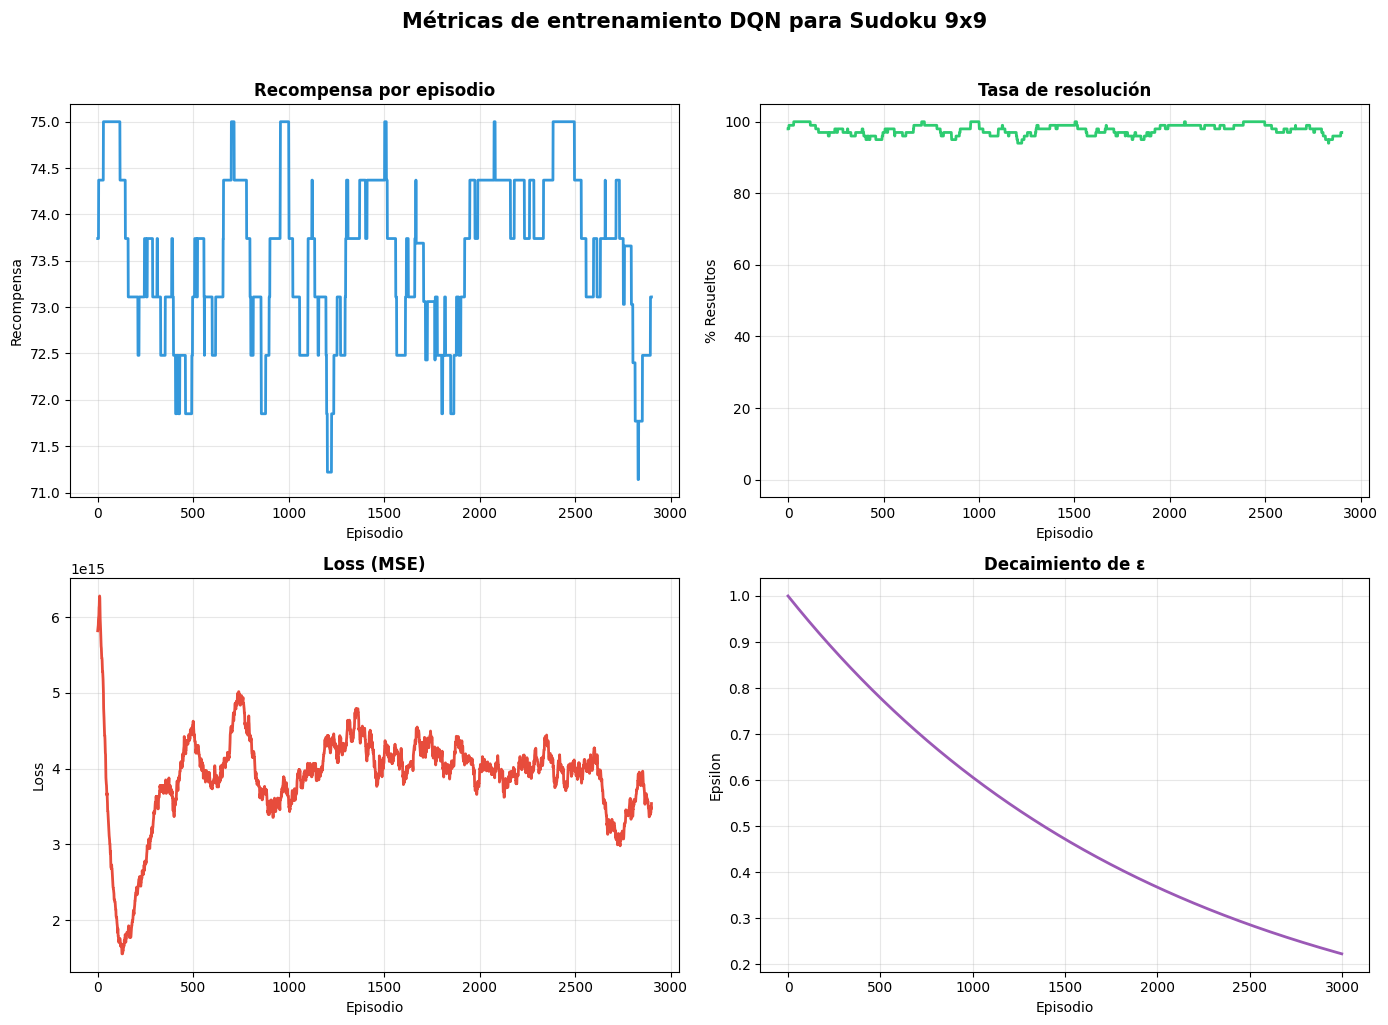

In [12]:
agente.plot_entrenamiento(ventana=100)

### Nivel 2: Puzzles con 15 celdas vacías (medio)

=== ENTRENAMIENTO DQN: 25 celdas vacías ===
  Ep   500/5000 | Resueltos:  62.0% | R media:    93.8 | ε: 0.9048 | Buffer: 7041
  Ep  1000/5000 | Resueltos:  62.0% | R media:    94.1 | ε: 0.8187 | Buffer: 14081
  Ep  1500/5000 | Resueltos:  63.0% | R media:    94.8 | ε: 0.7408 | Buffer: 21131
  Ep  2000/5000 | Resueltos:  64.2% | R media:    95.6 | ε: 0.6703 | Buffer: 28208
  Ep  2500/5000 | Resueltos:  62.2% | R media:    94.8 | ε: 0.6065 | Buffer: 35281
  Ep  3000/5000 | Resueltos:  64.4% | R media:    95.7 | ε: 0.5488 | Buffer: 42361
  Ep  3500/5000 | Resueltos:  64.0% | R media:    95.5 | ε: 0.4966 | Buffer: 49430
  Ep  4000/5000 | Resueltos:  60.0% | R media:    92.9 | ε: 0.4493 | Buffer: 50000
  Ep  4500/5000 | Resueltos:  63.4% | R media:    95.1 | ε: 0.4065 | Buffer: 50000
  Ep  5000/5000 | Resueltos:  63.0% | R media:    94.9 | ε: 0.3678 | Buffer: 50000

  Entrenamiento completo!
  Tasa final (ult 1000): 63.2%
  Total resueltos: 3141/5000


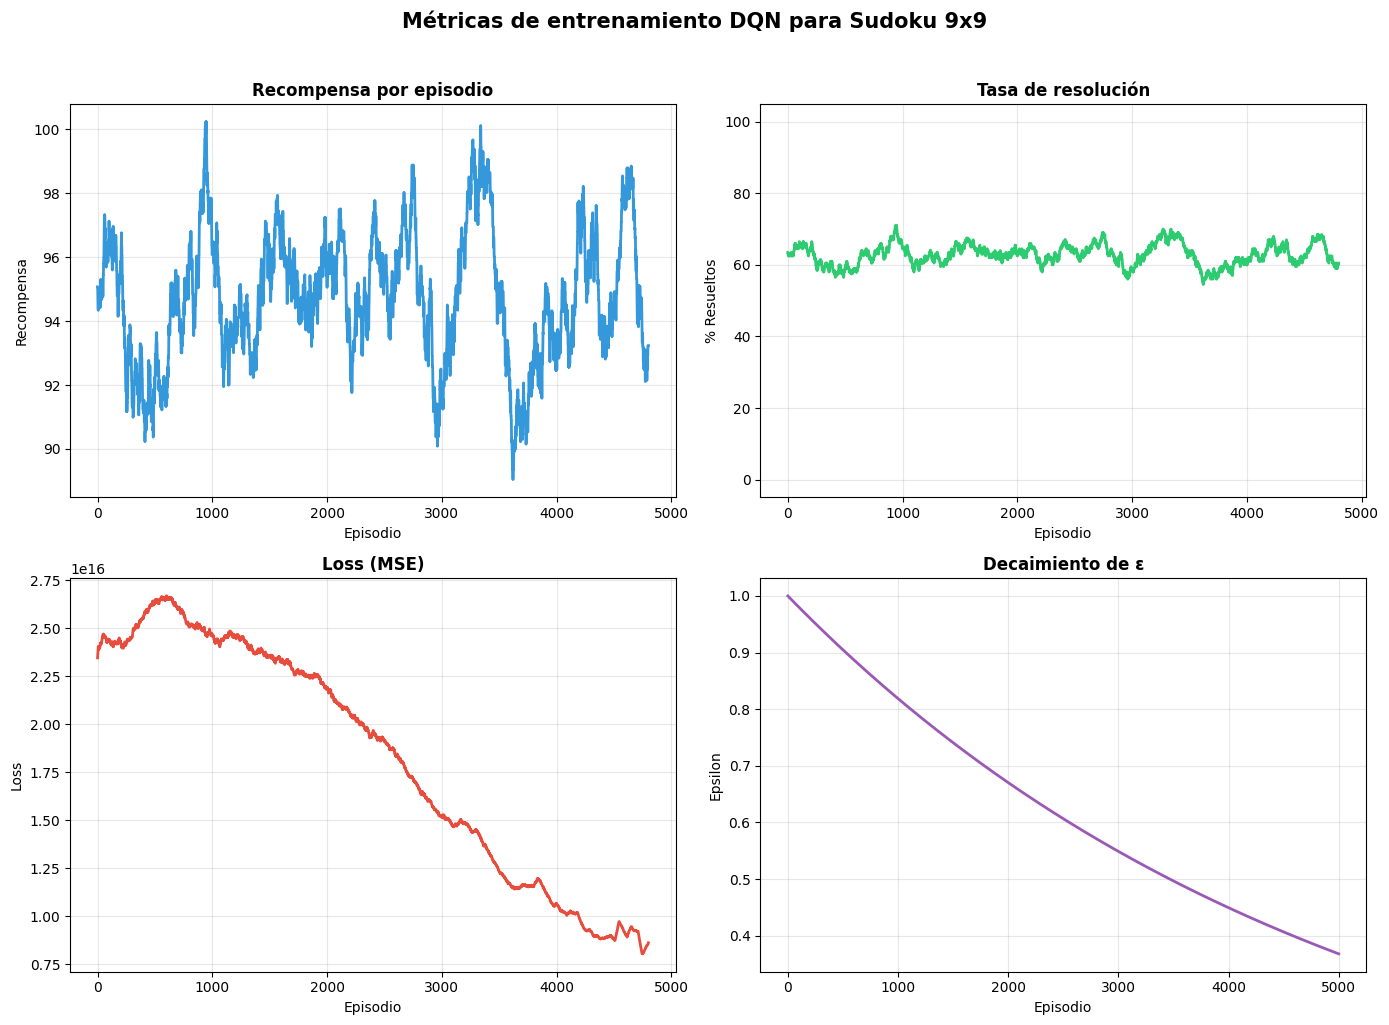

In [14]:
np.random.seed(42)
random.seed(42)
torch.manual_seed(42)

print('=== ENTRENAMIENTO DQN: 25 celdas vacías ===')

agente_medio = AgenteDQN(
    lr=3e-4,
    gamma=0.99,
    epsilon_inicio=1.0,
    epsilon_fin=0.05,
    epsilon_decay=0.9998,
    batch_size=64,
    target_update=500,
    buffer_size=50000
)

agente_medio.entrenar(n_episodios=5000, n_vacias=15, max_pasos=50)
agente_medio.plot_entrenamiento(ventana=200)

---

## Paso 8: Demo — el agente resuelve puzzles

=== DEMO: Agente DQN resolviendo Sudoku 9x9 ===
Celdas vacías: 6

  Paso 1: (4,5)=6 R=+5 ✓
  Paso 2: (0,0)=8 R=+5 ✓
  Paso 3: (8,4)=8 R=+5 ✓
  Paso 4: (0,4)=7 R=+5 ✓
  Paso 5: (1,0)=1 R=+5 ✓
  Paso 6: (3,7)=6 R=+50 ✓


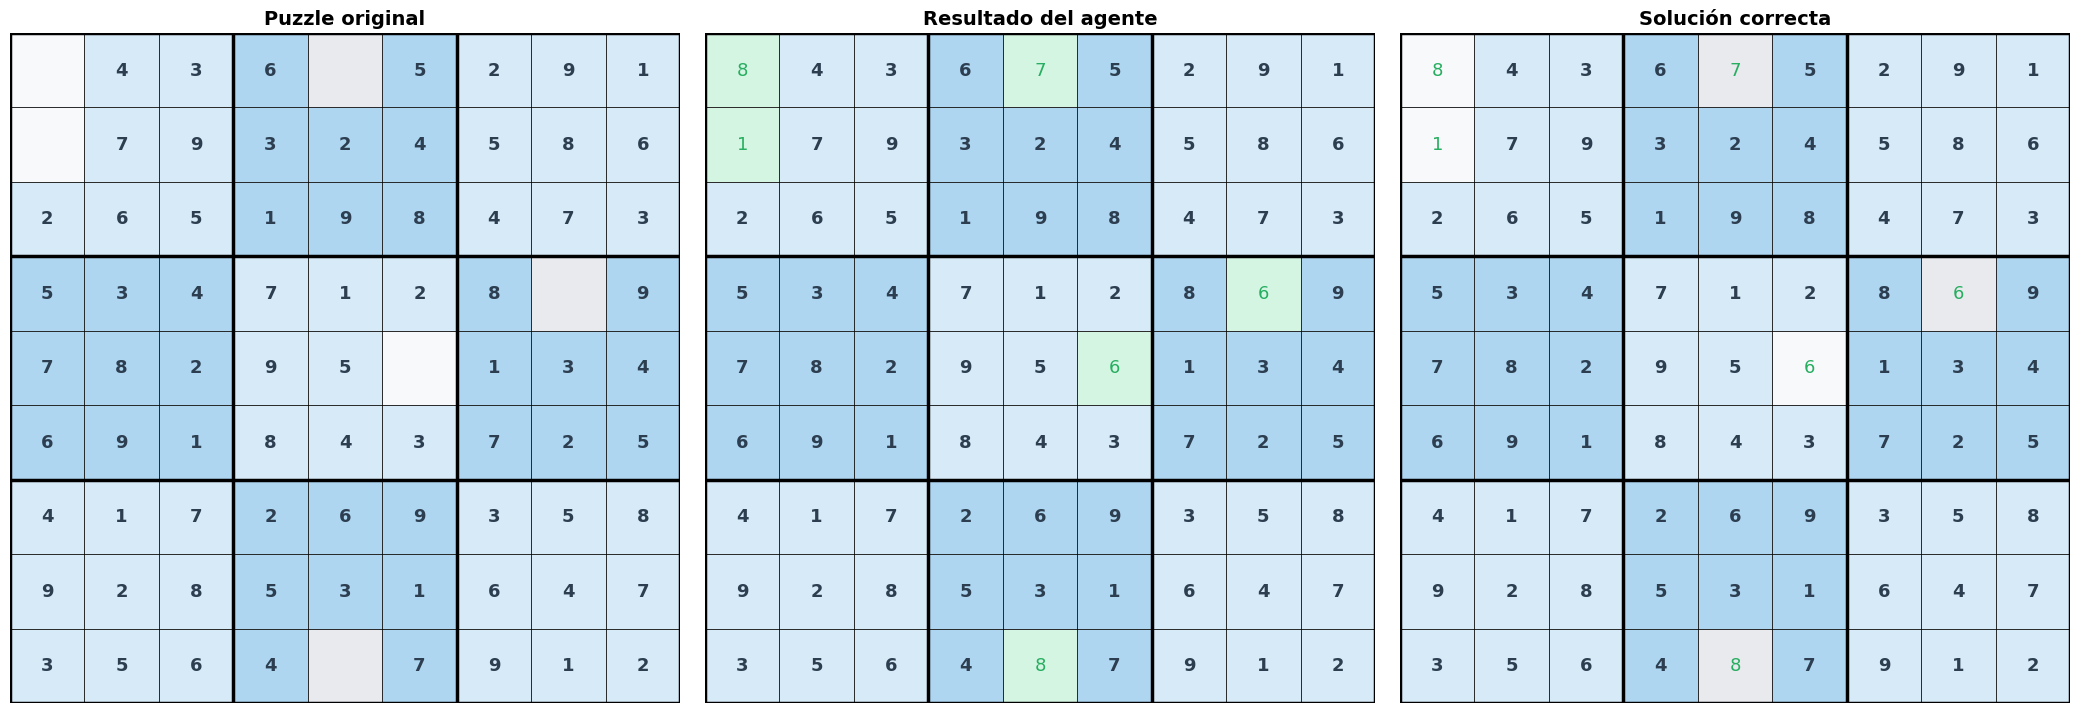


¡RESUELTO en 6 pasos!


In [17]:
# Demo: resolver un puzzle nuevo
np.random.seed(123)
env_demo = Sudoku9x9Env(n_vacias=6)
estado_demo = env_demo.reset()

print('=== DEMO: Agente DQN resolviendo Sudoku 9x9 ===')
print(f'Celdas vacías: {env_demo.n_vacias_actual}\n')

# Guardar estado inicial
tablero_inicial = env_demo.tablero.copy()

# Resolver
resuelto, movs = agente.resolver(env_demo, verbose=True)

# Visualizar
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# Restaurar tablero inicial para render
env_antes = Sudoku9x9Env(n_vacias=15)
env_antes.reset()
env_antes.tablero = tablero_inicial
env_antes.celdas_fijas = env_demo.celdas_fijas
env_antes.solucion = env_demo.solucion
env_antes.render('Puzzle original', ax=axes[0])

env_demo.render('Resultado del agente', ax=axes[1])
env_demo.render('Solución correcta', ax=axes[2], mostrar_solucion=True)
plt.tight_layout(); plt.show()

if resuelto:
    print(f'\n¡RESUELTO en {len(movs)} pasos!')
else:
    correctos = sum(1 for _, _, _, _, info in movs if info.get('correcto'))
    print(f'\nNo resuelto. Movimientos correctos: {correctos}/{len(movs)}')

In [19]:
# Evaluación masiva
def evaluar_dqn(agente, n_puzzles=50, n_vacias=15):
    """Evalúa el agente en múltiples puzzles."""
    resultados = {'resueltos': 0, 'correctos': 0, 'total_movs': 0, 'puzzles': n_puzzles}

    for i in range(n_puzzles):
        env_eval = Sudoku9x9Env(n_vacias=n_vacias)
        env_eval.reset()
        ok, movs = agente.resolver(env_eval, verbose=False)

        if ok:
            resultados['resueltos'] += 1
        correctos = sum(1 for _, _, _, _, info in movs if info.get('correcto'))
        resultados['correctos'] += correctos
        resultados['total_movs'] += len(movs)

    return resultados


print('=== Evaluación en puzzles nuevos ===')
print(f'{"Dificultad":<20} {"Resueltos":<15} {"Tasa":<10} {"Mov correctos %"}')
print('-' * 60)

for nombre, ag, n_v in [('6 vacías (fácil)', agente, 15),
                          ('15 vacías (medio)', agente_medio, 25)]:
    np.random.seed(999)
    res = evaluar_dqn(ag, n_puzzles=50, n_vacias=n_v)
    tasa = res['resueltos'] / res['puzzles'] * 100
    pct_corr = res['correctos'] / max(res['total_movs'], 1) * 100
    print(f'{nombre:<20} {res["resueltos"]}/{res["puzzles"]:<12} {tasa:>5.1f}%    {pct_corr:>5.1f}%')

=== Evaluación en puzzles nuevos ===
Dificultad           Resueltos       Tasa       Mov correctos %
------------------------------------------------------------
6 vacías (fácil)     33/50            66.0%     96.9%
15 vacías (medio)    3/50             6.0%     87.1%


---

## Paso 9: Análisis — ¿Qué aprendió la red?

Examinemos los Q-values que produce la red para entender su "razonamiento".

Q-values para las primeras 5 celdas vacías:
Celda    Solución      Q(1)    Q(2)    Q(3)    Q(4)    Q(5)    Q(6)    Q(7)    Q(8)    Q(9)   Mejor
----------------------------------------------------------------------------------------------------
(1,5)  7              -      -      -      -      -      - -61732.51→     -      -   7 ✓
(3,1)  7              -      -      -      -      -      - -2207.23→     -      -   7 ✓
(4,2)  1         -1482.40→     -      -      -      -      -      -      -      -   1 ✓
(5,0)  6              -      -      -      -      - 2169.15→     -      -      -   6 ✓
(6,3)  1         2957.87→     -      -      -      -      -      -      -      -   1 ✓


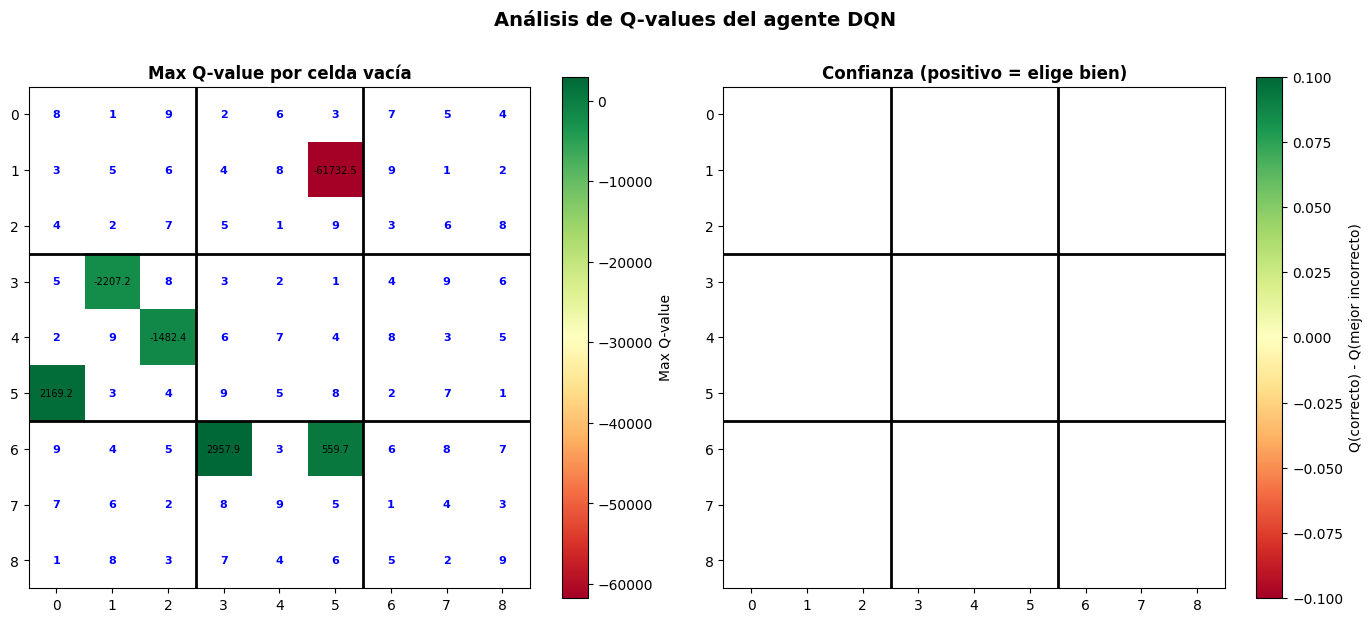

Verde = alta confianza en la respuesta correcta
Rojo = confusión o preferencia por respuesta incorrecta


In [20]:
# Analizar Q-values para un puzzle específico
np.random.seed(42)
env_analisis = Sudoku9x9Env(n_vacias=6)
estado_a = env_analisis.reset()

# Obtener Q-values
agente.q_network.eval()
with torch.no_grad():
    estado_t = torch.FloatTensor(estado_a).unsqueeze(0).to(device)
    mascara = env_analisis.obtener_mascara_acciones()
    mascara_t = torch.FloatTensor(mascara).unsqueeze(0).to(device)
    q_vals = agente.q_network(estado_t, mascara_t).cpu().numpy()[0]

# Para cada celda vacía, mostrar los Q-values de cada dígito
vacias = [(i, j) for i in range(9) for j in range(9) if env_analisis.tablero[i, j] == 0]

print('Q-values para las primeras 5 celdas vacías:')
print(f'{"Celda":<8} {"Solución":<10}', end='')
for d in range(1, 10):
    print(f'{"Q("+str(d)+")":>8}', end='')
print(f'{"  Mejor":>8}')
print('-' * 100)

for fila, col in vacias[:5]:
    sol = env_analisis.solucion[fila, col]
    print(f'({fila},{col})  {sol:<10}', end='')
    q_celda = []
    for d in range(1, 10):
        idx = env_analisis._codificar_accion(fila, col, d)
        q = q_vals[idx]
        q_celda.append((d, q))
        es_valido = mascara[idx] > 0
        marca = '→' if d == sol and es_valido else ' '
        if q > -1e8:
            print(f'{q:>7.2f}{marca}', end='')
        else:
            print(f'     - ', end='')

    mejor_d = max(q_celda, key=lambda x: x[1])[0]
    acierto = '✓' if mejor_d == sol else '✗'
    print(f'  {mejor_d} {acierto}')

# Heatmap de Q-values máximos por celda
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Mejor Q-value por celda
q_max_grid = np.full((9, 9), np.nan)
for i in range(9):
    for j in range(9):
        if env_analisis.tablero[i, j] == 0:
            q_celda = []
            for d in range(1, 10):
                idx = env_analisis._codificar_accion(i, j, d)
                if mascara[idx] > 0:
                    q_celda.append(q_vals[idx])
            if q_celda:
                q_max_grid[i, j] = max(q_celda)

ax = axes[0]
im = ax.imshow(q_max_grid, cmap='RdYlGn', interpolation='nearest')
plt.colorbar(im, ax=ax, label='Max Q-value')
for i in range(9):
    for j in range(9):
        if not np.isnan(q_max_grid[i, j]):
            ax.text(j, i, f'{q_max_grid[i,j]:.1f}', ha='center', va='center', fontsize=7)
        else:
            ax.text(j, i, str(env_analisis.tablero[i,j]), ha='center', va='center',
                   fontsize=8, fontweight='bold', color='blue')
for k in [2.5, 5.5]:
    ax.axhline(y=k, color='black', linewidth=2)
    ax.axvline(x=k, color='black', linewidth=2)
ax.set_title('Max Q-value por celda vacía', fontweight='bold')

# Confianza: diferencia entre Q del dígito correcto vs incorrecto
confianza_grid = np.full((9, 9), np.nan)
for i in range(9):
    for j in range(9):
        if env_analisis.tablero[i, j] == 0:
            sol = env_analisis.solucion[i, j]
            idx_sol = env_analisis._codificar_accion(i, j, sol)
            if mascara[idx_sol] > 0:
                q_correcto = q_vals[idx_sol]
                otros = []
                for d in range(1, 10):
                    if d != sol:
                        idx_d = env_analisis._codificar_accion(i, j, d)
                        if mascara[idx_d] > 0:
                            otros.append(q_vals[idx_d])
                if otros:
                    confianza_grid[i, j] = q_correcto - max(otros)

ax = axes[1]
im2 = ax.imshow(confianza_grid, cmap='RdYlGn', interpolation='nearest')
plt.colorbar(im2, ax=ax, label='Q(correcto) - Q(mejor incorrecto)')
for i in range(9):
    for j in range(9):
        if not np.isnan(confianza_grid[i, j]):
            ax.text(j, i, f'{confianza_grid[i,j]:.1f}', ha='center', va='center', fontsize=7)
for k in [2.5, 5.5]:
    ax.axhline(y=k, color='black', linewidth=2)
    ax.axvline(x=k, color='black', linewidth=2)
ax.set_title('Confianza (positivo = elige bien)', fontweight='bold')

plt.suptitle('Análisis de Q-values del agente DQN', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

print('Verde = alta confianza en la respuesta correcta')
print('Rojo = confusión o preferencia por respuesta incorrecta')

---

## Resumen

### Arquitectura completa

```
Puzzle Sudoku 9x9
       │
       ▼
Codificación one-hot (10 canales × 9 × 9)
       │
       ▼
┌──────────────────────────────────┐
│  Conv2D(10→64, 3×3) + BN + ReLU  │
│  Conv2D(64→128, 3×3) + BN + ReLU │
│  Conv2D(128→128, 3×3) + BN + ReLU│
│  Flatten → Dense(512) + ReLU     │
│  Dense(729) → Q-values           │
│  + Máscara de acciones válidas   │
└──────────────────────────────────┘
       │
       ▼
Acción: (fila, col, dígito) con mayor Q
```

### Componentes de DQN

| Componente | Propósito |
|---|---|
| **Q-Network** | Aproxima Q(s,a) con CNN |
| **Target Network** | Estabiliza el target (copia congelada) |
| **Replay Buffer** | Rompe correlación temporal |
| **ε-greedy** | Balance exploración/explotación |
| **Máscara de acciones** | Garantiza movimientos válidos |
| **Gradient clipping** | Estabilidad numérica |
| **Batch Normalization** | Estabiliza capas convolucionales |

### Lecciones del Sudoku con DQN

1. **La codificación importa**: one-hot encoding permite que la CNN detecte patrones
2. **La máscara de acciones es esencial**: sin ella, el agente perdería tiempo en acciones inválidas
3. **El diseño de recompensas es clave**: recompensar movimientos correctos intermedios acelera el aprendizaje
4. **DQN escala mejor que Q-Learning tabular**: puede manejar espacios de estado grandes
5. **Limitaciones**: para Sudoku con muchas celdas vacías (40+), se necesitarían técnicas más avanzadas (Double DQN, Dueling DQN, curiosity-driven exploration)